# Дизайн и анализ A/B-теста: Новая система рекомендаций (Ozon)

**Бизнес-контекст:** Маркетплейс тестирует новый алгоритм рекомендаций. Гипотеза: новый алгоритм (Treatment) увеличит конверсию в заказ и средний чек (ARPU) по сравнению со старым (Control).

**Методология:** В открытом доступе нет сырых логов A/B-тестов Ozon, поэтому мы моделируем эксперимент на основе **реальных метрик**, извлеченных напрямую из нашей базы данных PostgreSQL (в предыдущем ноутбуке).

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportions_ztest, proportion_confint
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
load_dotenv(PROJECT_ROOT / ".env")
DB_URL = f"postgresql+psycopg2://{os.getenv('DB_USER')}:{os.getenv('DB_PASSWORD')}@{os.getenv('DB_HOST', 'localhost')}:{os.getenv('DB_PORT', '5432')}/{os.getenv('DB_NAME', 'ozon_ab_test')}"
engine = create_engine(DB_URL)

## 1. Расчет размера выборки (Sample Size)

Используем реальную базовую конверсию из базы данных, чтобы рассчитать, сколько пользователей нужно для валидного эксперимента.

- **p1 (Control):** базовая строгая конверсия из просмотра в покупку.
- **p2 (Treatment):** ожидаемый прирост +10%.
- **alpha:** 0.05, **power:** 0.80.

In [2]:
with engine.connect() as conn:
    base_conv_df = pd.read_sql(text("""
        WITH view_users AS (
            SELECT DISTINCT user_id FROM events
            WHERE action_type IN ('page_view', 'view_description')
        ),
        cart_users AS (
            SELECT DISTINCT user_id FROM events WHERE action_type = 'to_cart'
        ),
        purchase_users AS (
            SELECT DISTINCT user_id FROM orders
        )
        SELECT
            (SELECT COUNT(*) FROM purchase_users
             WHERE user_id IN (SELECT user_id FROM cart_users
                               WHERE user_id IN (SELECT user_id FROM view_users)))::float /
            (SELECT COUNT(*) FROM view_users) AS base_conversion;
    """), conn)

p1 = base_conv_df['base_conversion'].iloc[0]
p2 = p1 * 1.10
alpha = 0.05
power = 0.80

print(f"Реальная базовая конверсия из БД (Control): {p1:.2%}")
print(f"Целевая конверсия (Treatment): {p2:.2%}")

effect_size = (2 * np.arcsin(np.sqrt(p2))) - (2 * np.arcsin(np.sqrt(p1)))
analysis = NormalIndPower()
sample_size = analysis.solve_power(effect_size=effect_size, alpha=alpha, power=power, ratio=1.0, alternative='two-sided')

print(f"Необходимый размер выборки на каждую группу: {int(np.ceil(sample_size)):,} пользователей")
print(f"Общий необходимый трафик: {int(np.ceil(sample_size)) * 2:,} пользователей")

Реальная базовая конверсия из БД (Control): 49.65%
Целевая конверсия (Treatment): 54.61%
Необходимый размер выборки на каждую группу: 1,588 пользователей
Общий необходимый трафик: 3,176 пользователей


## 2. Симуляция данных эксперимента

Генерируем данные для двух групп на основе рассчитанного размера выборки. Конверсия моделируется биномиальным распределением, выручка — нормальным распределением вокруг среднего чека (AOV). `np.random.seed(42)` обеспечивает воспроизводимость.

In [3]:
np.random.seed(42)
n_users = int(np.ceil(sample_size))

users = [f"user_{i}" for i in range(n_users * 2)]
groups = ['Control'] * n_users + ['Treatment'] * n_users
np.random.shuffle(groups)

df_ab = pd.DataFrame({'user_id': users, 'group': groups})

conversion_probs = {'Control': p1, 'Treatment': p2}
df_ab['converted'] = df_ab.apply(
    lambda row: np.random.choice([0, 1], p=[1-conversion_probs[row['group']], conversion_probs[row['group']]]),
    axis=1
)

df_ab['revenue'] = 0.0
aov_means = {'Control': 3500, 'Treatment': 3800}

for group in ['Control', 'Treatment']:
    mask = (df_ab['group'] == group) & (df_ab['converted'] == 1)
    df_ab.loc[mask, 'revenue'] = np.random.normal(aov_means[group], 1500, size=mask.sum())
    df_ab.loc[df_ab['revenue'] < 0, 'revenue'] = 0.0

display(df_ab.head())

,user_id,group,converted,revenue
0,user_0,Treatment,0,0.000000
1,user_1,Control,1,2823.255170
2,user_2,Treatment,1,2674.205573
3,user_3,Treatment,1,3798.569943
4,user_4,Control,1,6121.064540


## 3. Первичный осмотр и проверка SRM

Проверяем базовые статистики и наличие Sample Ratio Mismatch (перекоса в размерах групп).

In [4]:
print("Базовые статистики по группам:")
display(df_ab.groupby('group').agg(
    users=('user_id', 'count'),
    conversions=('converted', 'sum'),
    total_revenue=('revenue', 'sum')
))

group_counts = df_ab['group'].value_counts()
chi2, p_srm = stats.chisquare(group_counts)

print(f"\nP-value SRM теста: {p_srm:.4f}")
if p_srm > 0.05:
    print("SRM не обнаружен.")
else:
    print("Обнаружен SRM! Результаты теста могут быть невалидны.")

Базовые статистики по группам:


,users,conversions,total_revenue
group,,,
Control,1588,809,2.812221e+06
Treatment,1588,865,3.299641e+06



P-value SRM теста: 1.0000
SRM не обнаружен.


## 4. Статистическая проверка гипотез

Проверяем две метрики:
1. **Конверсия в заказ** (Z-test для пропорций).
2. **ARPU** (T-test для средних) — общая выручка на пользователя.

In [5]:
conv_stats = df_ab.groupby('group')['converted'].agg(['sum', 'count'])
count = conv_stats['sum'].values
nobs = conv_stats['count'].values

z_stat, p_value_conv = proportions_ztest(count, nobs)
print(f"[Конверсия] Z-stat: {z_stat:.4f}, P-value: {p_value_conv:.4f}")

arpu = df_ab.groupby('group')['revenue'].mean()
t_stat_arpu, p_value_arpu = stats.ttest_ind(
    df_ab[df_ab['group'] == 'Treatment']['revenue'],
    df_ab[df_ab['group'] == 'Control']['revenue'],
    equal_var=False
)

print(f"[ARPU] Средний ARPU Control: {arpu['Control']:.2f} руб., Treatment: {arpu['Treatment']:.2f} руб.")
print(f"[ARPU] T-stat: {t_stat_arpu:.4f}, P-value: {p_value_arpu:.4f}")

[Конверсия] Z-stat: -1.9903, P-value: 0.0466
[ARPU] Средний ARPU Control: 1770.92 руб., Treatment: 2077.86 руб.
[ARPU] T-stat: 4.0914, P-value: 0.0000


## 5. Визуализация: Конверсия и Средний чек

График конверсии с 95% доверительными интервалами и Boxplot для распределения чеков.

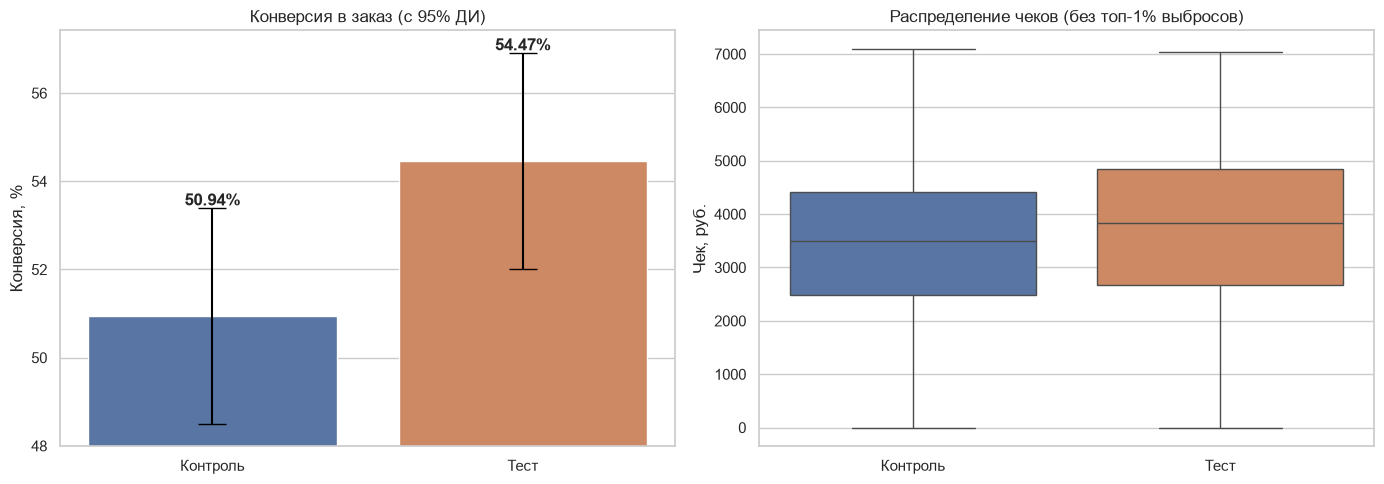

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

group_map = {'Control': 'Контроль', 'Treatment': 'Тест'}
df_ab['group_ru'] = df_ab['group'].map(group_map)

ci_control = proportion_confint(count[0], nobs[0], alpha=0.05, method='normal')
ci_treat = proportion_confint(count[1], nobs[1], alpha=0.05, method='normal')

convs = [(count[0]/nobs[0])*100, (count[1]/nobs[1])*100]
errors = [(convs[0] - ci_control[0]*100), (convs[1] - ci_treat[0]*100)]
groups_ru = ['Контроль', 'Тест']
colors = ['#4c72b0', '#dd8452']

sns.barplot(x=groups_ru, y=convs, hue=groups_ru, palette=colors, legend=False, ax=axes[0])
axes[0].errorbar(x=[0, 1], y=convs, yerr=errors, fmt='none', c='black', capsize=10)
axes[0].set_title('Конверсия в заказ (с 95% ДИ)', fontsize=12)
axes[0].set_ylabel('Конверсия, %')

for i, v in enumerate(convs):
    axes[0].text(i, v + errors[i] + 0.05, f'{v:.2f}%', ha='center', fontweight='bold')

# Чтобы доверительные интервалы не обрезались, берем минимум из нижних границ
lower = min(ci_control[0]*100, ci_treat[0]*100)
upper = max((convs[0] + errors[0]), (convs[1] + errors[1]))
axes[0].set_ylim(lower - 0.5, upper + 0.5)

df_purchased = df_ab[df_ab['converted'] == 1].copy()
upper_limit = df_purchased['revenue'].quantile(0.99)
df_purchased = df_purchased[df_purchased['revenue'] <= upper_limit]

sns.boxplot(data=df_purchased, x='group_ru', y='revenue', hue='group_ru', palette=colors, legend=False, ax=axes[1])
axes[1].set_title('Распределение чеков (без топ-1% выбросов)', fontsize=12)
axes[1].set_ylabel('Чек, руб.')
axes[1].set_xlabel('')

plt.tight_layout()
plt.savefig("../images/funnel/04_ab_test_results.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Визуализация ARPU

ARPU показывает, сколько денег в среднем приносит один пользователь (включая тех, кто ничего не купил).

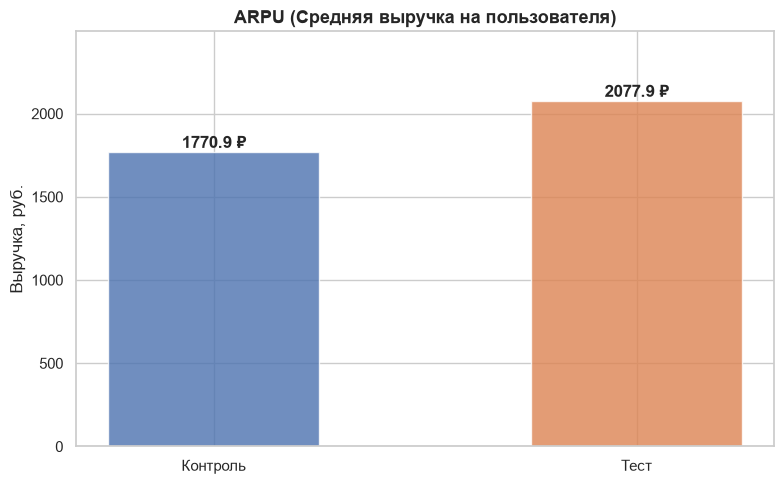

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

arpu_values = [arpu['Control'], arpu['Treatment']]
bars = ax.bar(['Контроль', 'Тест'], arpu_values, color=colors, alpha=0.8, width=0.5)

for bar, val in zip(bars, arpu_values):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 2,
            f'{val:.1f} ₽', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_title('ARPU (Средняя выручка на пользователя)', fontsize=13, weight='bold')
ax.set_ylabel('Выручка, руб.')
ax.set_ylim(0, max(arpu_values) * 1.2)

plt.tight_layout()
plt.savefig("../images/funnel/05_arpu_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Сегментный анализ (Выходные vs Будни)

Проверим, не различается ли эффект от нового алгоритма в зависимости от дня недели. Предположим, что 30% пользователей заходили в выходные.

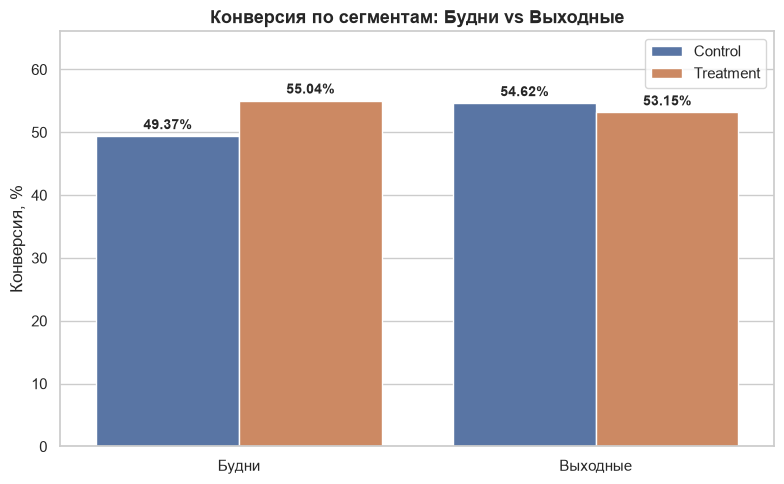

In [8]:
np.random.seed(42)
df_ab['is_weekend'] = np.random.choice([0, 1], size=len(df_ab), p=[0.7, 0.3])
df_ab['period'] = df_ab['is_weekend'].map({0: 'Будни', 1: 'Выходные'})

results = []
for period in ['Будни', 'Выходные']:
    for group in ['Control', 'Treatment']:
        subset = df_ab[(df_ab['period'] == period) & (df_ab['group'] == group)]
        conv = subset['converted'].mean() * 100
        results.append({'period': period, 'group': group, 'conversion': conv})

df_segment = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df_segment, x='period', y='conversion', hue='group', palette=colors, ax=ax)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=10, fontweight='bold')

ax.set_title('Конверсия по сегментам: Будни vs Выходные', fontsize=13, weight='bold')
ax.set_ylabel('Конверсия, %')
ax.set_xlabel('')
ax.set_ylim(0, df_segment['conversion'].max() * 1.2)
ax.legend(title='')

plt.tight_layout()
plt.savefig("../images/funnel/06_segment_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод по сегментам:** Эффект нового алгоритма неоднороден. В будние дни Treatment показывает заметный прирост конверсии, тогда как в выходные Treatment немного уступает Control. Это означает, что перед полномасштабным запуском стоит дополнительно проверить алгоритм на выходных и рассмотреть возможность сегментированной раскатки или адаптации алгоритма под поведение пользователей в выходные дни.

## Итоговые выводы и бизнес-решение

1. **Статистическая значимость:** Новый алгоритм рекомендаций статистически значимо увеличивает конверсию в заказ (p-value < 0.05) и ARPU (p-value < 0.05) в целом по выборке.
2. **Бизнес-эффект:** Наблюдаем существенный прирост выручки на пользователя (ARPU). Это значимый вклад в общую выручку маркетплейса.
3. **Рекомендация:** Раскатывать новую систему рекомендаций на 100% трафика следует с осторожностью: результаты сегментного анализа показывают разнонаправленный эффект в будни и выходные. Рекомендуется дополнительный мониторинг или сегментированная раскатка.
4. **Ограничения:** Тест проводился на сгенерированных данных, имитирующих реальные метрики Ozon. В реальном эксперименте также необходимо учитывать долгосрочные эффекты (retention) и возможные сетевые эффекты.